# 02 — ngspice vs analytical

Created with Grok Build

Compare the ideal-VCVS and full **OPA365** macromodel AC response to the
analytical $H_{\mathrm{vin}}(s)$.

**Custom netlist:** replace the `simulate_ac(...)` calls with
`run_external_netlist(Path("your.cir"), workdir=...)` and parse your own
`wrdata` files (see comments in `opamp_design.simulate`).


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Directory that contains opamp_design/. Works when this notebook is run
# from the standalone repo (repo root or notebooks/) or from this website
# section (the folder that holds these notebooks and opamp_design/).
def _find_project_root() -> Path:
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig86")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "opamp_design" / "__init__.py").is_file():
            return cand
    return start

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from opamp_design.params import CircuitParams, OpampParams, ToleranceSpec, format_eng
from opamp_design import analysis, schematic

# -----------------------------------------------------------------------------
# EDITABLE PARAMETERS — change R/C/tolerances here for what-if studies.
# For a completely different netlist, keep these as documentation of the
# stimulus/supply and drive opamp_design.simulate.run_external_netlist(...)
# with your own .cir instead of the Fig. 8-6 generators.
# -----------------------------------------------------------------------------
R1 = 1.8e3       # ohms
R2 = 19.5e3
R3 = 150e3
C1 = 3.3e-9      # farads
C2 = 47e-12
C3 = 220e-12
R_TOL = 0.001    # 0.1% as fraction
C_TOL = 0.01     # 1% as fraction
V_SUPPLY = 5.0
V_IN_BIAS = 2.5
V_IN_PEAK = 2.5
F_DESIGN = 20e3

p = CircuitParams(
    R1=R1, R2=R2, R3=R3, C1=C1, C2=C2, C3=C3,
    r_tol=ToleranceSpec(R_TOL),
    c_tol=ToleranceSpec(C_TOL),
)
# Operating point overrides
from dataclasses import replace
p = replace(p, op=replace(p.op, v_supply=V_SUPPLY, v_in_bias=V_IN_BIAS,
                          v_in_peak=V_IN_PEAK, f_design_hz=F_DESIGN))

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT)
print("R1..C3 =", p.passive_dict())


ROOT = .
R1..C3 = {'R1': 1800.0, 'R2': 19500.0, 'R3': 150000.0, 'C1': 3.3e-09, 'C2': 4.7e-11, 'C3': 2.2e-10}


In [2]:
from opamp_design.simulate import simulate_ac, compare_ac_to_analytical, find_ngspice
from opamp_design.analysis import transfer_at_s

print("ngspice:", find_ngspice())

# --- Ideal op-amp + explicit non-ideal sources (fair match to analysis) ---
wd_ideal = ROOT / "results" / "ngspice_nom" / "ideal_ac"
ac_i = simulate_ac(
    p, opamp_model="ideal", workdir=wd_ideal, root=ROOT,
    mirror=ROOT / "netlists" / "spice_nom" / "fig86_ac_ideal.cir",
)

# --- TI OPA365 macromodel ---
wd_ic = ROOT / "results" / "ngspice_nom" / "opa365_ac"
ac_o = simulate_ac(
    p, opamp_model="opa365", workdir=wd_ic, root=ROOT,
    mirror=ROOT / "netlists" / "spice_nom" / "fig86_ac_opa365.cir",
)

def analytical_on_grid(f):
    return np.array([transfer_at_s(1j * 2 * np.pi * fi, p, "vin") for fi in f])

h_a_i = analytical_on_grid(ac_i.f_hz)
h_a_o = analytical_on_grid(ac_o.f_hz)
err_i = compare_ac_to_analytical(ac_i, h_a_i)
err_o = compare_ac_to_analytical(ac_o, h_a_o)
display(pd.DataFrame([{"model": "ideal", **err_i}, {"model": "OPA365", **err_o}]))

ngspice: ngspice


,model,max_abs_err_db,rms_err_db,max_abs_phase_err_deg
0,ideal,0.000013,0.000009,0.000016
1,OPA365,40.115125,7.979073,98.670288


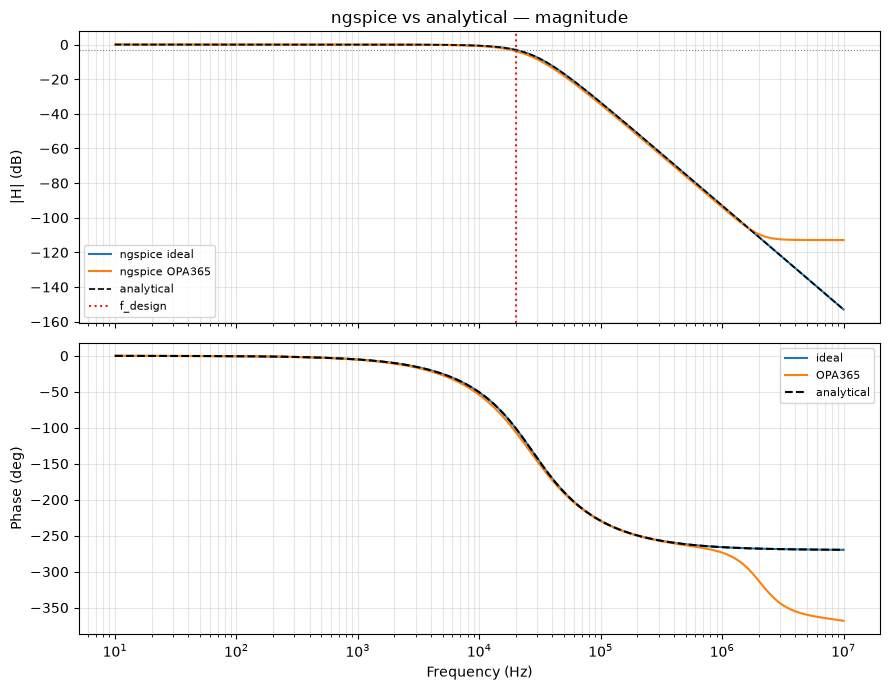

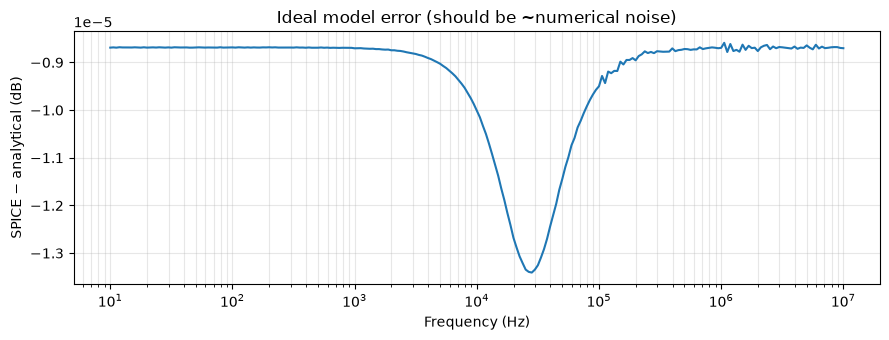

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for ac, lab, c in (
    (ac_i, "ngspice ideal", "C0"),
    (ac_o, "ngspice OPA365", "C1"),
):
    axes[0].semilogx(ac.f_hz, ac.mag_db, label=lab, lw=1.5)
axes[0].semilogx(ac_i.f_hz, 20*np.log10(np.maximum(np.abs(h_a_i),1e-30)),
                 "k--", label="analytical", lw=1.2)
axes[0].axhline(-3, color="gray", ls=":", lw=0.8)
axes[0].axvline(p.op.f_design_hz, color="C3", ls=":", label="f_design")
axes[0].set_ylabel("|H| (dB)")
axes[0].set_title("ngspice vs analytical — magnitude")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)

for ac, lab in ((ac_i, "ideal"), (ac_o, "OPA365")):
    axes[1].semilogx(ac.f_hz, np.unwrap(np.angle(ac.h, deg=True)*np.pi/180)*180/np.pi, label=lab)
axes[1].semilogx(ac_i.f_hz, np.unwrap(np.angle(h_a_i))*180/np.pi, "k--", label="analytical")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (deg)")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "02_ngspice_vs_analytical.png", dpi=150)
plt.show()

# Error vs frequency (ideal)
err_db = ac_i.mag_db - 20*np.log10(np.maximum(np.abs(h_a_i),1e-30))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogx(ac_i.f_hz, err_db)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("SPICE − analytical (dB)")
ax.set_title("Ideal model error (should be ~numerical noise)")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "02_ideal_error_db.png", dpi=150)
plt.show()

## Passband transient at 10 kHz

The AC source used above is a 1 V phasor. The time-domain source is that same amplitude about the 2.5 V bias:

$$V_{\mathrm{in}}(t) = 2.5 + \sin(2\pi\cdot 10\,\mathrm{kHz}\,t)\ \mathrm{V}.$$

10 kHz is an octave below the 20 kHz design edge, so the filter is in its passband. The run is 1.5 ms. Gain and phase are a least-squares sine fit on the last 0.5 ms, five cycles after the third-order startup has settled.

The figure below is `results/figures/Figure_8_6_3_pole_SK_10kHz_tran.png`, exported from `LTSpice/Figure_8_6_3_pole_SK_10kHz_tran.asc` (the AC schematic with the source changed to `SINE(2.5 1 10k)`). The traces below solve the ideal voltage-controlled voltage source, which is the network in the analytical model. One extra ngspice trace uses a local OPA365 macromodel when that file is present.


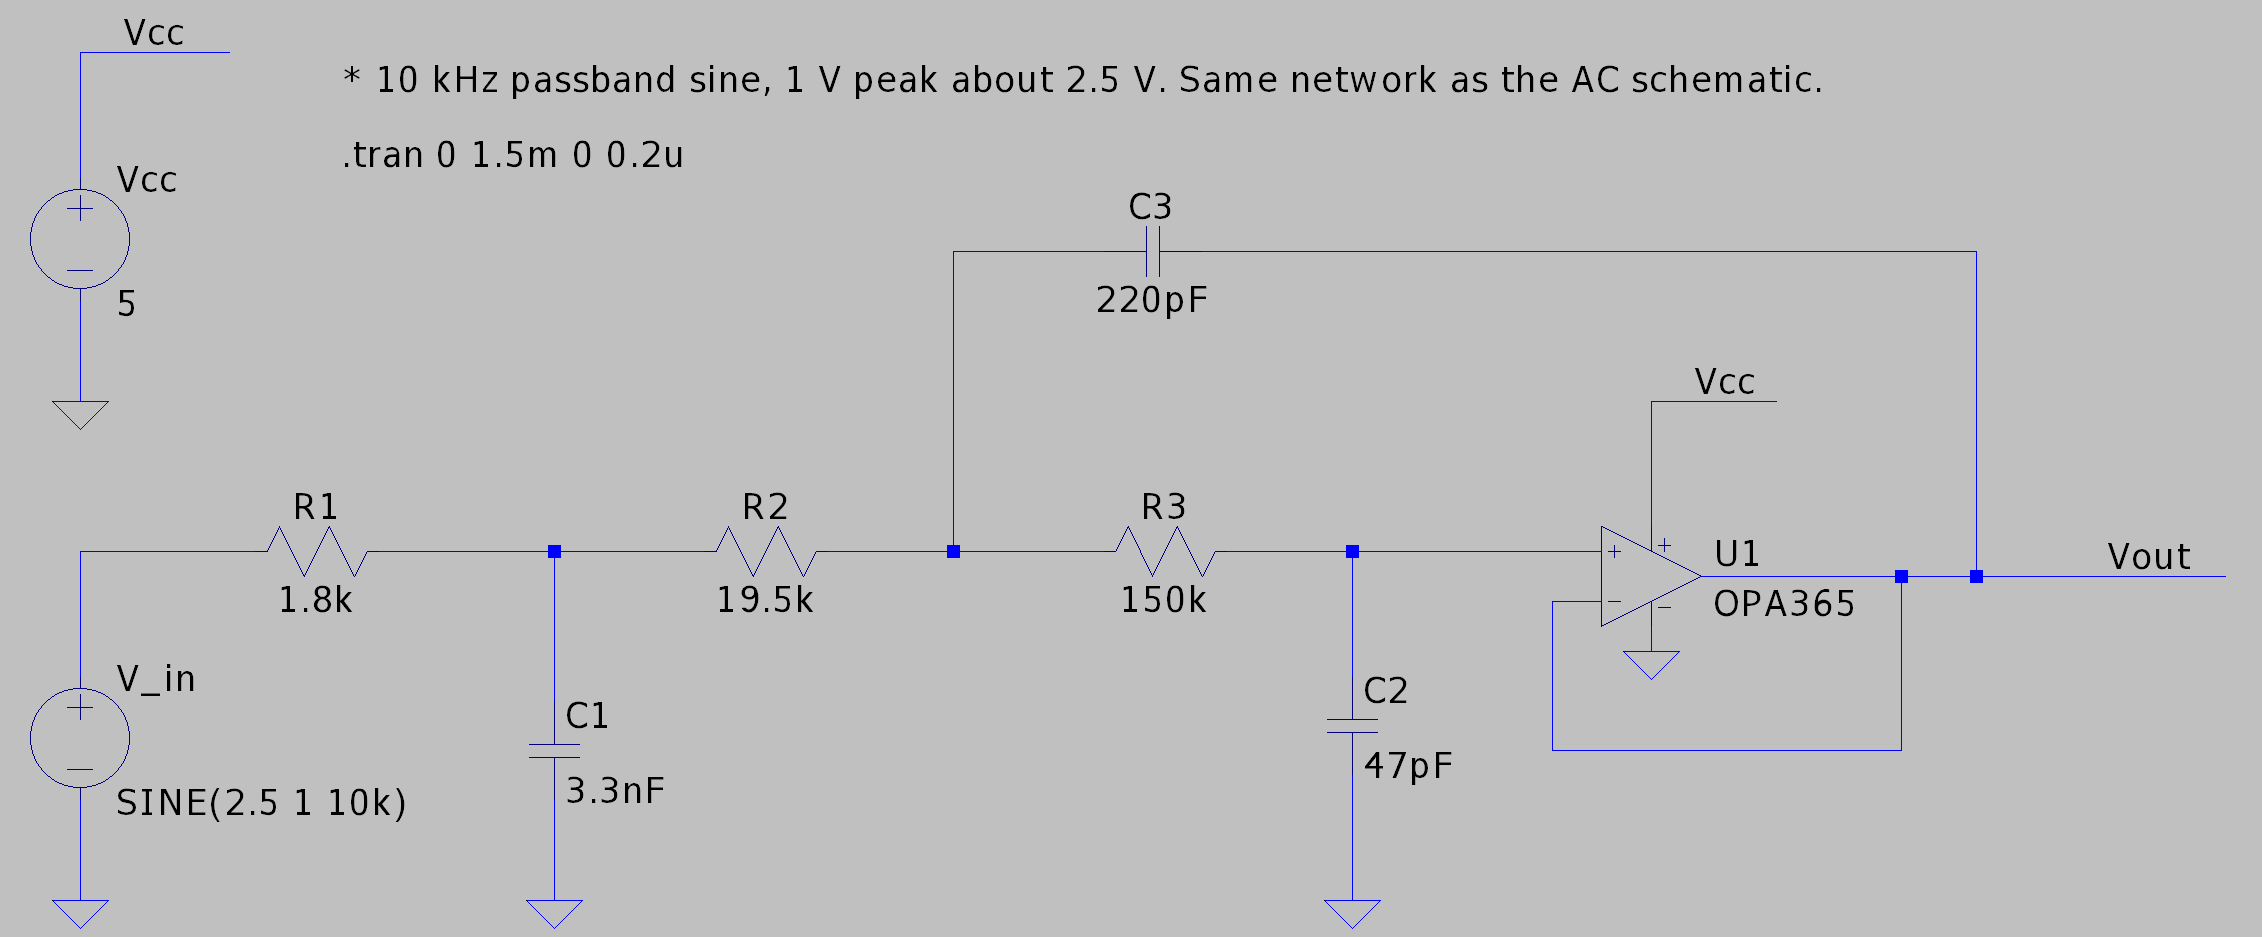

In [10]:
from IPython.display import Image, display

# Exported from LTSpice/Figure_8_6_3_pole_SK_10kHz_tran.asc
spath = FIG / "Figure_8_6_3_pole_SK_10kHz_tran.png"
display(Image(filename=str(spath), width=1100))


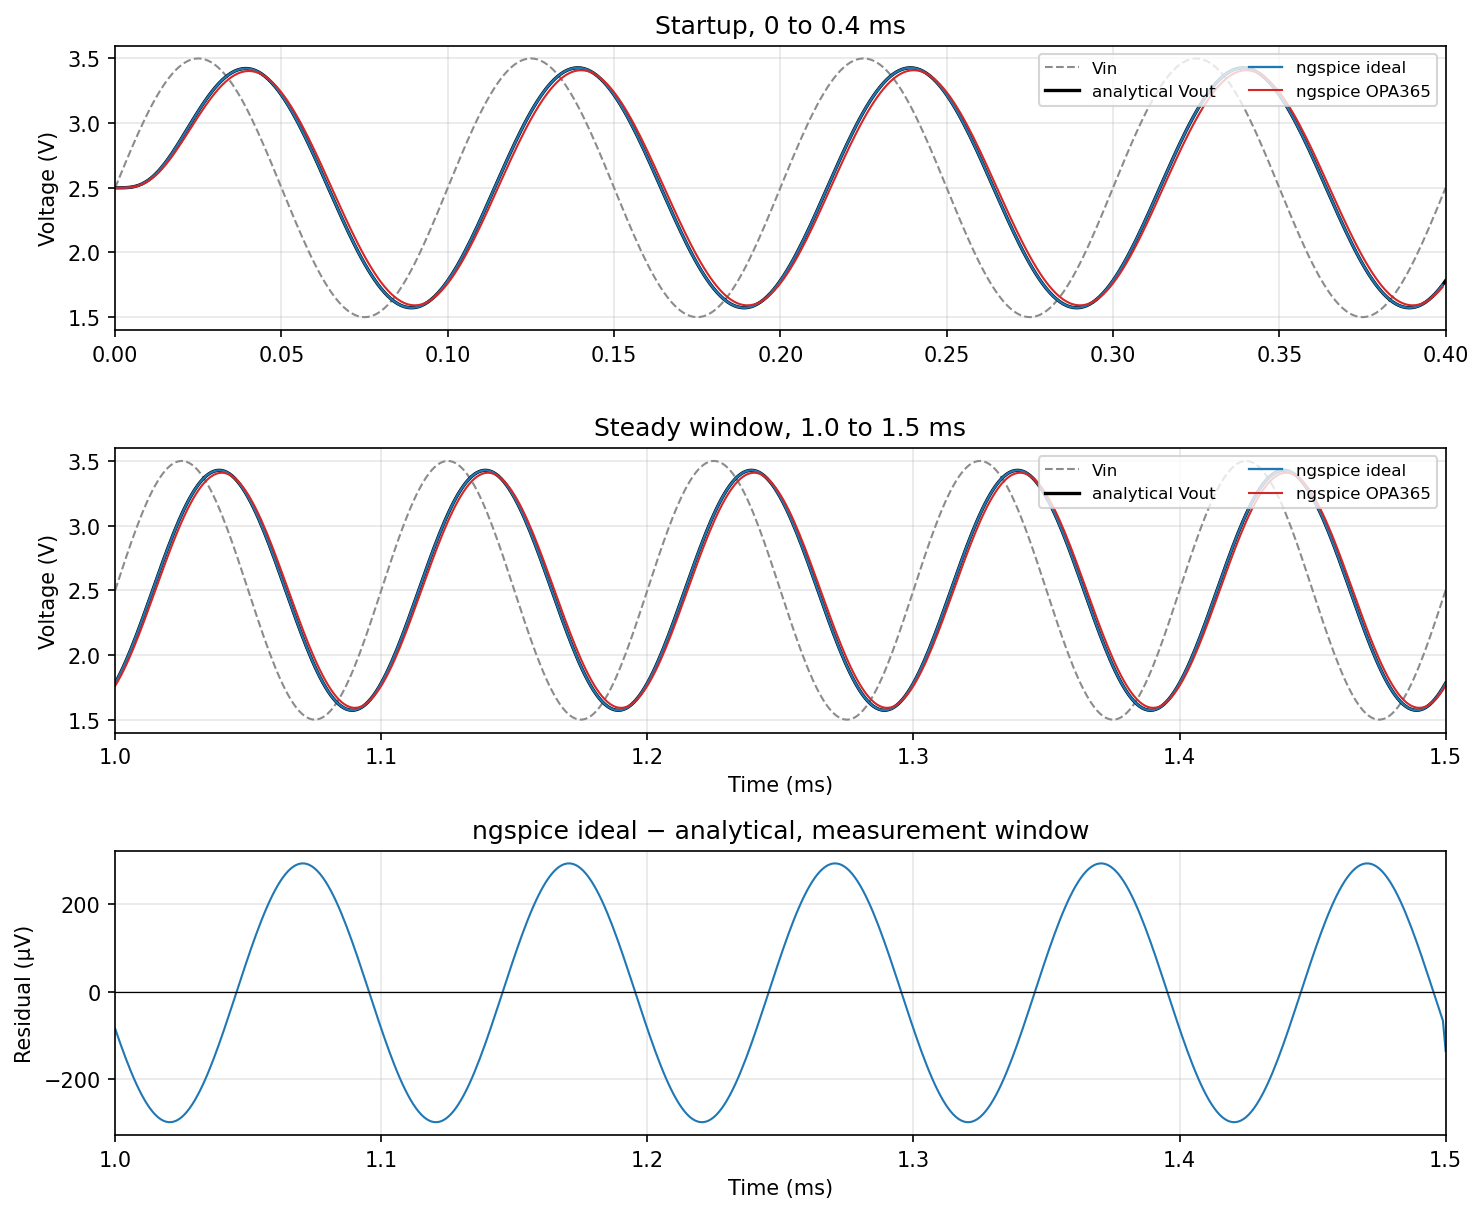

model,gain,phase_deg,gain_error,phase_error_deg
analytical H(jω),0.927440,-50.712,0.000e+00,0.0000
ngspice ideal,0.927390,-50.729,-5.066e-05,-0.0169
ngspice OPA365,0.908808,-54.318,-1.863e-02,-3.6064


Window residual RMS = 208.55 µV (peak 297.4 µV).


In [11]:
from opamp_design.simulate import simulate_tran
from opamp_design.transient import (
    F_PASSBAND_HZ,
    TRAN_AMP_V,
    TRAN_MEAS_FROM_S,
    TRAN_TSTOP_S,
    analytical_tone,
    analytical_waveform,
    measure_tone,
    resolve_opa365_lib,
)

freq = F_PASSBAND_HZ
t = np.linspace(0.0, TRAN_TSTOP_S, 1501)
vin_a, vout_a = analytical_waveform(p, t, freq_hz=freq, amp_v=TRAN_AMP_V)
tone_a = analytical_tone(p, freq_hz=freq, amp_v=TRAN_AMP_V)

ideal = simulate_tran(
    p,
    opamp_model="ideal",
    workdir=ROOT / "results" / "tran" / "nom_ngspice",
    root=ROOT,
    freq_hz=freq,
    amp_v=TRAN_AMP_V,
)
tone_ng = measure_tone(ideal.time, ideal.vin, ideal.vout, freq_hz=freq, t_min=TRAN_MEAS_FROM_S)

lib = resolve_opa365_lib(ROOT)
oa = None
tone_oa = None
if lib is None:
    print("OPA365 macromodel is not in models/opa365/; the ideal trace is the comparison.")
else:
    try:
        oa = simulate_tran(
            p,
            opamp_model="opa365",
            workdir=ROOT / "results" / "tran" / "nom_opa365",
            root=ROOT,
            lib_path=lib,
            freq_hz=freq,
            amp_v=TRAN_AMP_V,
            timeout_s=120,
        )
        tone_oa = measure_tone(oa.time, oa.vin, oa.vout, freq_hz=freq, t_min=TRAN_MEAS_FROM_S)
    except Exception:
        print("OPA365 macromodel transient did not complete; the ideal trace is the comparison.")
        oa = None
        tone_oa = None

def _mask(time, t0, t1):
    return (time >= t0) & (time <= t1)

fig, axes = plt.subplots(3, 1, figsize=(10, 8.2))
panels = (
    (axes[0], 0.0, 0.4e-3, "Startup, 0 to 0.4 ms"),
    (axes[1], TRAN_MEAS_FROM_S, TRAN_TSTOP_S, "Steady window, 1.0 to 1.5 ms"),
)
for ax, t0, t1, title in panels:
    m = _mask(t, t0, t1)
    ax.plot(t[m] * 1e3, vin_a[m], color="0.55", lw=1.0, ls="--", label="Vin")
    ax.plot(t[m] * 1e3, vout_a[m], color="k", lw=1.6, label="analytical Vout")
    mn = _mask(ideal.time, t0, t1)
    ax.plot(ideal.time[mn] * 1e3, ideal.vout[mn], color="C0", lw=1.1, label="ngspice ideal")
    if oa is not None:
        mo = _mask(oa.time, t0, t1)
        ax.plot(oa.time[mo] * 1e3, oa.vout[mo], color="C3", lw=1.0, label="ngspice OPA365")
    ax.set_xlim(t0 * 1e3, t1 * 1e3)
    ax.set_ylabel("Voltage (V)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, ncol=2, loc="upper right")
axes[1].set_xlabel("Time (ms)")

m = _mask(t, TRAN_MEAS_FROM_S, TRAN_TSTOP_S)
vout_ng_i = np.interp(t[m], ideal.time, ideal.vout)
resid_uv = (vout_ng_i - vout_a[m]) * 1e6
axes[2].plot(t[m] * 1e3, resid_uv, color="C0", lw=1.0)
axes[2].axhline(0.0, color="k", lw=0.6)
axes[2].set_xlim(TRAN_MEAS_FROM_S * 1e3, TRAN_TSTOP_S * 1e3)
axes[2].set_xlabel("Time (ms)")
axes[2].set_ylabel("Residual (µV)")
axes[2].set_title("ngspice ideal − analytical, measurement window")
axes[2].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "02_tran_10khz.png", dpi=150)
plt.show()

rows = [
    {
        "model": "analytical H(jω)",
        "gain": tone_a.gain,
        "phase_deg": tone_a.phase_deg,
        "gain_error": 0.0,
        "phase_error_deg": 0.0,
    },
    {
        "model": "ngspice ideal",
        "gain": tone_ng.gain,
        "phase_deg": tone_ng.phase_deg,
        "gain_error": tone_ng.gain - tone_a.gain,
        "phase_error_deg": tone_ng.phase_deg - tone_a.phase_deg,
    },
]
if tone_oa is not None:
    rows.append(
        {
            "model": "ngspice OPA365",
            "gain": tone_oa.gain,
            "phase_deg": tone_oa.phase_deg,
            "gain_error": tone_oa.gain - tone_a.gain,
            "phase_error_deg": tone_oa.phase_deg - tone_a.phase_deg,
        }
    )
table = pd.DataFrame(rows)
show = table.copy()
show["gain"] = show["gain"].map(lambda v: f"{v:.6f}")
show["phase_deg"] = show["phase_deg"].map(lambda v: f"{v:.3f}")
show["gain_error"] = show["gain_error"].map(lambda v: f"{v:.3e}")
show["phase_error_deg"] = show["phase_error_deg"].map(lambda v: f"{v:.4f}")
display(show)
print(
    f"Window residual RMS = {np.sqrt(np.mean(resid_uv**2)):.2f} µV "
    f"(peak {np.max(np.abs(resid_uv)):.1f} µV)."
)


### Reading the transient

The ideal solver and the analytical waveform overlie each other. In the measurement window the difference peaks near 300 µV. That is the 0.017° phase offset on the 1 µs sample grid; the gain itself agrees to about 50 ppm. The OPA365 macromodel, when it is present, is a device model: its gain sits a little below the ideal network and its phase lags a few degrees more. Later notebooks keep the ideal source so ngspice, LTspice, and the nodal solution are the same linear circuit.

The startup has died well before 1 ms, which is why the fit uses the last five cycles.
